# Learning gradient descent from first principles: NumPy and PyTorch

###Prof. Victor S. Batista
**CHEM 584: Introduction to Machine Learning and Quantum Computing**




## Beginner tutorial + graded homework (100 points)

**Big question:** How can a computer learn a curve from examples instead of being told its equation?

We will give the computer sample pairs $(x,y)$ from $y=\sin(x)$ and ask it to learn a **cubic polynomial** that approximates them. We start with one prediction and one error, then build up to matrix notation, gradients, training, and finally PyTorch.

**Prior knowledge:** basic Python; familiarity with graphs and elementary algebra. Differentiation is reviewed briefly where it is used. **No machine-learning background is assumed.**

**Learning outcomes:** Explain features and targets; construct polynomial features and an intercept column; calculate a prediction and squared error by hand; explain how gradients change parameters; implement gradient descent; interpret learning curves; understand the difference between NumPy and PyTorch's autograd.

**Directions:** Run cells top to bottom in Google Colab or Jupyter. Read each **Stop and predict** question before revealing its output. Sections 1–10 are guided examples. Section 11 contains the homework you will submit. See the rubric and checklist at the end.


## 1. From data to a prediction: what are we learning?

Suppose we observe pairs of numbers: an **input** $x$ and an **output** $y$. In machine-learning language, $x$ is a *feature* and $y$ is the *target*. A **model** is a rule that uses an input to predict an output $\hat y$ (pronounced “y-hat”).

A simple **straight-line model** is $\hat y=b+mx$. Its two adjustable numbers are $b$ (the **intercept**, the height at $x=0$) and $m$ (the **slope**). A line cannot reproduce every curved pattern.

To represent a bend, we can add $x^2$; to allow a more flexible curve, we add $x^3$:

$$\hat y=\theta_0+\theta_1 z+\theta_2 z^2+\theta_3 z^3,\qquad z=x/\pi.$$

This is a **degree-3 polynomial** (a *cubic*). The degree is the largest power. A “polynomial expansion” does **not** invent new observations: it turns each single input $z$ into several numerical features $z,z^2,z^3$. Their coefficients $\theta_1,\theta_2,\theta_3$ can be learned separately.

**Why use $z=x/\pi$?** Our $x$ values are between $-\pi$ and $\pi$, so $z$ is between $-1$ and $1$. This keeps powers from becoming unnecessarily large. We still plot results against the original $x$.

### The intercept and the column of ones

For $z=0$, the prediction is $\theta_0$. So $\theta_0$ controls the vertical offset, even when the other terms are zero. We can write $\theta_0$ as $1\times\theta_0$; this explains the **leading 1** in each feature row. Without that constant feature (or an equivalent separate bias), the model would always predict zero at $z=0$ and could not shift vertically.

### Worked example (one observation)

At $z=2/3$, the expanded row is $[1,\;2/3,\;4/9,\;8/27]$. If the coefficients are $(1,2,0,-1)$, then

$$\hat y=1+2(2/3)+0(4/9)-(8/27)\approx 2.037.$$

**Stop and predict:** What is the feature row for $z=0$? What happens to $\hat y$ at $z=0$ if we change only $\theta_0$?

### Why a design matrix?

A **design matrix** is just a table: **one row per observation** and **one column per model feature**. For $N$ inputs,

$$X=\begin{bmatrix}1&z_1&z_1^2&z_1^3\\\vdots&\vdots&\vdots&\vdots\\1&z_N&z_N^2&z_N^3\end{bmatrix}.$$

The four-coefficient column vector is $\boldsymbol\theta=(\theta_0,\theta_1,\theta_2,\theta_3)^T$. Multiplying gives **all predictions at once**: $\hat{\mathbf y}=X\boldsymbol\theta$. This notation is convenient, not a new model.

**Shape check:** $X$ is `(N, 4)`, coefficients are `(4,)`, and predicted targets are `(N,)`.


In [ ]:
import time
import numpy as np
import matplotlib.pyplot as plt
import torch

# Fix the seeds so that the initial parameters are reproducible.
SEED = 2026
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)

# float64 makes the comparison of analytical and numerical gradients reliable.
DTYPE = torch.float64
N = 2000                # Number of training samples
DEGREE = 3              # Polynomial degree (four coefficients)
REGULARIZATION = 1e-3   # Penalty strength, often called lambda

x = np.linspace(-np.pi, np.pi, N)
y = np.sin(x)
z = x / np.pi

# Each row is [1, z_i, z_i^2, z_i^3].
X = np.polynomial.polynomial.polyvander(z, DEGREE)
initial_theta = rng.standard_normal(DEGREE + 1)

print('NumPy version:', np.__version__)
print('PyTorch version:', torch.__version__)
print('X.shape =', X.shape)
print('y.shape =', y.shape)
print('initial_theta.shape =', initial_theta.shape)
print('First design-matrix row:', X[0])

NumPy version: 2.1.3
PyTorch version: 2.11.0+cpu
X.shape = (2000, 4)
y.shape = (2000,)
initial_theta.shape = (4,)
First design-matrix row: [ 1. -1.  1. -1.]


### 1.1 Build one row by hand before asking NumPy

For a single scaled input $z=0.5$, powers of $z$ are $z^0=1$, $z^1=0.5$, $z^2=0.25$, and $z^3=0.125$. The code below performs the expansion explicitly. **Stop and predict:** What would change if `z_example` were `0` or `-1`?

In [ ]:
z_example = 0.5
feature_row = [1, z_example, z_example**2, z_example**3]
theta_example = [1, 2, 0, -1]
prediction_by_hand = sum(feature * coefficient for feature, coefficient in zip(feature_row, theta_example))
print('Expanded feature row:', feature_row)
print('Coefficients:', theta_example)
print('One predicted y:', prediction_by_hand)
# Note: this toy example is separate from the sine-fitting dataset below.

Expanded feature row: [1, 0.5, 0.25, 0.125]
Coefficients: [1, 2, 0, -1]
One predicted y: 1.875


### Visualize the data and the untrained model

The initial coefficients are random, so the untrained polynomial generally fits poorly. Training means adjusting the four parameters to reduce the prediction error.

### 1.2 Inspect a tiny design matrix

Below we make a **three-row table** for $z=-1,0,1$. This is the same operation that `np.polynomial.polynomial.polyvander` performs for the full dataset. The output makes the intercept column and the changing powers visible.

In [ ]:
tiny_z = np.array([-1.0, 0.0, 1.0])
tiny_X = np.column_stack([np.ones(3), tiny_z, tiny_z**2, tiny_z**3])
print('Columns = [1, z, z^2, z^3]')
print(tiny_X)
print('Shape:', tiny_X.shape)
print('At z=0, prediction is the intercept:', tiny_X[1] @ initial_theta)
np.testing.assert_allclose(tiny_X, np.polynomial.polynomial.polyvander(tiny_z, 3))

Columns = [1, z, z^2, z^3]
[[ 1. -1.  1. -1.]
 [ 1.  0.  0.  0.]
 [ 1.  1.  1.  1.]]
Shape: (3, 4)
At z=0, prediction is the intercept: -0.7931224751578991


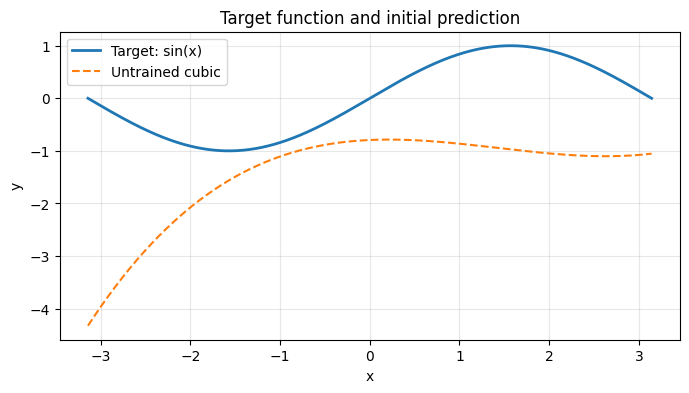

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(x, y, label='Target: sin(x)', linewidth=2)
plt.plot(x, X @ initial_theta, '--', label='Untrained cubic')
plt.xlabel('x'); plt.ylabel('y')
plt.title('Target function and initial prediction')
plt.legend(); plt.grid(alpha=0.3); plt.show()

## 2. How does the computer decide whether a fit is good?

For each input, the **residual** is $r_i=\hat y_i-y_i$. The mean squared error is $N^{-1}\sum_i r_i^2$. We add a **ridge penalty** to discourage unnecessarily large polynomial coefficients:

$$\boxed{L(\boldsymbol\theta)=\frac1N\lVert X\boldsymbol\theta-\mathbf y\rVert_2^2+\lambda\lVert\boldsymbol\theta\rVert_2^2.}$$

Here $\lambda=10^{-3}$. For simplicity **all four coefficients, including the intercept**, are penalized. This detail matters: it must be implemented consistently in NumPy, PyTorch, and the direct solver.

The number $L$ is a single **scalar**. The smaller it is, the better the balance between fitting the data and keeping the coefficients small.

### Vocabulary check: observation, parameter, prediction

There are `N` observations (each provides an $x$ and a target $y$), but only **four learned coefficients**. The data are fixed during training; the coefficients are updated. The plotted *untrained* curve uses random coefficients and is not expected to match sine.

**Stop and predict:** If the polynomial degree increases from 3 to 5, how many coefficients will there be *including the intercept*?

In [ ]:
def numpy_loss(theta):
    """Compute mean squared error plus ridge penalty for any 4-vector theta."""
    prediction = X @ theta           # Shape: (N,)
    residual = prediction - y        # Shape: (N,)
    mse = np.mean(residual ** 2)      # One scalar
    penalty = REGULARIZATION * np.sum(theta ** 2)
    return float(mse + penalty)

print(f'Initial loss: {numpy_loss(initial_theta):.6f}')

Initial loss: 2.791110


### 2.1 From one error to a loss over the dataset

For one example, if the true output is $y=2$ and our prediction is $\hat y=3$, the **residual** is $r=\hat y-y=1$ and the **squared error** is $r^2=1$. If the prediction is $0$, the squared error is $(-2)^2=4$.

For many examples, the **mean squared error (MSE)** is their average:
$$\mathrm{MSE}=\frac1N\sum_{i=1}^N(\hat y_i-y_i)^2.$$

We also add a *small optional penalty* for large coefficients, called **ridge regularization**. Think of it as preferring a simpler, smaller-coefficient curve when two curves fit similarly:
$$L=\mathrm{MSE}+\lambda(\theta_0^2+\theta_1^2+\theta_2^2+\theta_3^2).$$

Here $\lambda=0.001$. **For this lesson, even the intercept is penalized**, so every method uses exactly the same loss. Students should first understand MSE, then treat the penalty as a small extension. $L$ is the one number we aim to minimize.

**Stop and predict:** If every residual were zero, would the full regularized loss always be zero? Why or why not?

In [ ]:
# A deliberately tiny, transparent loss calculation
true_values = np.array([2.0, 0.0])
predicted_values = np.array([3.0, -2.0])
errors = predicted_values - true_values
squared_errors = errors**2
print('Residuals:', errors)
print('Squared errors:', squared_errors)
print('Mean squared error:', np.mean(squared_errors))  # (1 + 4) / 2 = 2.5

Residuals: [ 1. -2.]
Squared errors: [1. 4.]
Mean squared error: 2.5


## 3. Gradient descent: the mathematics

The **gradient** contains one derivative for each coefficient:

$$\nabla L=(\partial L/\partial\theta_0,\ldots,\partial L/\partial\theta_3)^\mathsf T.$$

Applying the chain rule to the squared residuals gives

$$\boxed{\nabla L(\boldsymbol\theta)=\frac{2}{N}X^\mathsf T(X\boldsymbol\theta-\mathbf y)+2\lambda\boldsymbol\theta.}$$

The first term measures how changing the coefficients affects the residuals. The second term is the derivative of the ridge penalty.

One **gradient descent step** is

$$\boldsymbol\theta\leftarrow\boldsymbol\theta-\eta\nabla L(\boldsymbol\theta),$$

where $\eta$ is the **learning rate** or step size. A very large learning rate may cause divergence; an extremely small one makes learning slow.

In [ ]:
def numpy_gradient(theta):
    """Analytical derivative of the same loss used by numpy_loss."""
    residual = X @ theta - y
    data_gradient = (2.0 / N) * (X.T @ residual)
    penalty_gradient = 2.0 * REGULARIZATION * theta
    return data_gradient + penalty_gradient

print('Gradient at the initial parameters:')
print(numpy_gradient(initial_theta))

Gradient at the initial parameters:
[-2.85331361  0.08414775 -1.29311885  0.24972633]


### 3.1 Why a gradient tells us which way to move

For a single weight $w$, consider $L(w)=(w-2)^2$. Calculus gives $dL/dw=2(w-2)$. At $w=0$, the derivative is $-4$, so increasing $w$ reduces the loss. At $w=4$, the derivative is $+4$, so decreasing $w$ reduces the loss.

For several weights, the **gradient** is a collection of these slopes: one partial derivative per coefficient. A gradient-descent update moves *opposite* the gradient:
$$\theta_j^{\mathrm{new}}=\theta_j^{\mathrm{old}}-\eta\,\frac{\partial L}{\partial\theta_j}.$$

The **learning rate** $\eta$ controls the step size. We use the same idea for all four coefficients at once. Differentiating our MSE plus ridge penalty gives the formula in the preceding section. The `2` comes from differentiating a square; the matrix transpose collects contributions across all observations.

**Optional calculus detail:** For one observation, $\partial(\hat y_i-y_i)^2/\partial\theta_j=2(\hat y_i-y_i)X_{ij}$. Average over all $i$ and add $2\lambda\theta_j$ to obtain the vector formula.

In [ ]:
# A one-parameter demonstration of a single gradient-descent step
w = 0.0
eta_demo = 0.1
slope = 2 * (w - 2)
w_new = w - eta_demo * slope
print('Before: weight =', w, 'loss =', (w-2)**2)
print('Gradient =', slope)
print('After:  weight =', w_new, 'loss =', (w_new-2)**2)

Before: weight = 0.0 loss = 4.0
Gradient = -4.0
After:  weight = 0.4 loss = 2.5600000000000005


### 3.1 Verify the gradient using finite differences

Before trusting a hand-derived gradient, perturb one parameter at a time:

$$\frac{\partial L}{\partial\theta_j}\approx\frac{L(\boldsymbol\theta+h\mathbf e_j)-L(\boldsymbol\theta-h\mathbf e_j)}{2h}.$$

This is called a **central finite difference**. It should agree with the analytical expression to numerical precision for a suitable small $h$.

In [ ]:
def finite_difference_gradient(loss_function, theta, h=1e-6):
    approximate_gradient = np.zeros_like(theta)
    for j in range(theta.size):
        perturbation = np.zeros_like(theta)
        perturbation[j] = h
        approximate_gradient[j] = (
            loss_function(theta + perturbation)
            - loss_function(theta - perturbation)
        ) / (2 * h)
    return approximate_gradient

analytic = numpy_gradient(initial_theta)
numeric = finite_difference_gradient(numpy_loss, initial_theta)
print('Analytical gradient:', analytic)
print('Finite-difference gradient:', numeric)
print('Largest absolute difference:', np.max(np.abs(analytic - numeric)))
np.testing.assert_allclose(analytic, numeric, rtol=1e-6, atol=1e-8)

Analytical gradient: [-2.85331361  0.08414775 -1.29311885  0.24972633]
Finite-difference gradient: [-2.85331361  0.08414775 -1.29311885  0.24972633]
Largest absolute difference: 5.725958041047363e-10


## 4. Train the model with NumPy

This loss is quadratic in the parameters. We can precompute

$$H=X^\mathsf TX/N+\lambda I,\qquad b=X^\mathsf T\mathbf y/N,$$

so that $\nabla L(\boldsymbol\theta)=2(H\boldsymbol\theta-b)$. Precomputation avoids repeatedly looping over all $N$ samples, making the example faster without changing the mathematics.

For a quadratic loss, the Hessian is $2H$. A convenient stable learning rate is the reciprocal of its largest eigenvalue. The term **eigenvalue** is not required for following the code; it is used here just to choose an appropriate step size automatically.

In [ ]:
H = (X.T @ X) / N + REGULARIZATION * np.eye(DEGREE + 1)
b = (X.T @ y) / N
hessian = 2.0 * H
learning_rate = 1.0 / np.linalg.eigvalsh(hessian).max()
print(f'Learning rate: {learning_rate:.5f}')

def numpy_gradient_descent(theta_start, steps=2500, record_every=10):
    theta = theta_start.copy()  # Never overwrite the original initialization.
    history = [(0, numpy_loss(theta))]
    start = time.perf_counter()

    for step_number in range(1, steps + 1):
        gradient = 2.0 * (H @ theta - b)
        theta -= learning_rate * gradient
        if step_number % record_every == 0 or step_number == steps:
            history.append((step_number, numpy_loss(theta)))

    return theta, np.asarray(history), time.perf_counter() - start

theta_numpy, history_numpy, time_numpy = numpy_gradient_descent(initial_theta)
print('Trained parameters:', theta_numpy)
print('Final loss:', numpy_loss(theta_numpy))

Learning rate: 0.44566
Trained parameters: [-1.25722864e-16  2.57239535e+00 -2.20110041e-18 -2.70830357e+00]
Final loss: 0.019169628199232177


### What the NumPy training loop does

One *iteration* computes the slope for each coefficient, subtracts `learning_rate * gradient`, then repeats. The special matrix `H` in the code below is only a speed-up for our particular quadratic loss: it gives **the same gradient** as `numpy_gradient(theta)`. You may focus first on the update `theta -= learning_rate * gradient`.

We select a stable step size automatically so that the first working example trains reliably. The eigenvalue calculation is an **advanced implementation detail**; the homework will explore what happens when you vary the rate.

## 5. Learn the essential PyTorch concepts

PyTorch uses **tensors** to store numbers and arrays. A tensor is similar to a NumPy array, but PyTorch can also track the operations used to compute results and automatically differentiate them.

A few useful ideas:

- `torch.tensor(...)` makes a new tensor from data.
- `dtype=torch.float64` chooses 64-bit floating-point numbers.
- `requires_grad=True` instructs PyTorch to track operations involving that tensor.
- `.backward()` applies the chain rule and stores gradients in `.grad`.
- `.detach()` creates a tensor view disconnected from gradient tracking; this is useful for displaying results.

**Important:** PyTorch accumulates gradients by default. We must clear old gradients before requesting new ones in an iterative training loop.

### Checkpoint: reading the training output

Compare `numpy_loss(initial_theta)` with `numpy_loss(theta_numpy)`. A successful run should produce a smaller final loss. **Important:** loss need not reach zero—our cubic is only an approximation to sine. A sequence of iterations is often called a **learning curve** when we plot loss against iteration.

In [ ]:
# Start with a small example independent of polynomial fitting.
a = torch.tensor(3.0, dtype=DTYPE, requires_grad=True)
value = a ** 2 + 2 * a   # f(a) = a^2 + 2a
value.backward()         # Compute df/da = 2a + 2

print('a =', a.item())
print('f(a) =', value.item())
print('Autograd df/da =', a.grad.item())
print('Expected df/da =', 2 * a.item() + 2)

# Repeating backward without clearing .grad would add to the previous value.

a = 3.0
f(a) = 15.0
Autograd df/da = 8.0
Expected df/da = 8.0


### 5.1 Transfer the data into PyTorch

We use **full-batch training**: every optimizer step evaluates the loss over all $N$ samples. PyTorch can also train on smaller batches, but batches are unnecessary for this short example.

The mathematical model and the regularization penalty must remain exactly the same so the implementations can be compared fairly.

In [ ]:
X_torch = torch.as_tensor(X, dtype=DTYPE)
y_torch = torch.as_tensor(y, dtype=DTYPE)

def pytorch_loss(theta):
    """The same scalar objective as numpy_loss, implemented with tensors."""
    residual = X_torch @ theta - y_torch
    mse = torch.mean(residual ** 2)
    penalty = REGULARIZATION * torch.sum(theta ** 2)
    return mse + penalty

# Compare the two loss implementations at identical parameters.
theta_test = torch.tensor(initial_theta, dtype=DTYPE, requires_grad=True)
loss_test = pytorch_loss(theta_test)
loss_test.backward()
print('NumPy loss:', numpy_loss(initial_theta))
print('PyTorch loss:', loss_test.item())
print('NumPy gradient:', numpy_gradient(initial_theta))
print('PyTorch gradient:', theta_test.grad.detach().numpy())
np.testing.assert_allclose(theta_test.grad.detach().numpy(),
                           numpy_gradient(initial_theta), rtol=1e-10, atol=1e-10)

NumPy loss: 2.791109826102765
PyTorch loss: 2.7911098261027645
NumPy gradient: [-2.85331361  0.08414775 -1.29311885  0.24972633]
PyTorch gradient: [-2.85331361  0.08414775 -1.29311885  0.24972633]


## 6. Train with PyTorch optimizers

PyTorch separates the **model parameters**, the **loss**, and the **optimizer**:

1. `torch.nn.Parameter` marks a tensor as a trainable parameter.
2. `optimizer.zero_grad()` clears the previous gradient.
3. `loss.backward()` computes the new gradient.
4. `optimizer.step()` updates the parameters.

We compare two optimizers:

**SGD (stochastic gradient descent)** performs a gradient step. Because we use the entire dataset, it is mathematically ordinary gradient descent in this notebook.

**Adam** automatically adapts parameter-wise step sizes using moving averages of gradients and squared gradients. This often makes tuning easier, though it need not be fastest for every problem.

In the code below, parameters are **not** edited manually after creating an optimizer: the optimizer owns the update.

### What changes in PyTorch?

**Nothing about the prediction formula or the loss changes.** NumPy requires us to write the derivative (the `numpy_gradient` function). PyTorch can calculate that derivative from the operations that produced the loss. The following cell first checks that both frameworks calculate the same value and gradient. Think of `requires_grad=True` as switching on a trace of the math operations; `.backward()` uses that trace to compute slopes.

In [ ]:
def train_with_pytorch(theta_start, optimizer_name, steps, lr, record_every=10):
    # A fresh Parameter ensures every method starts from the same coefficients.
    theta = torch.nn.Parameter(torch.tensor(theta_start.copy(), dtype=DTYPE))

    if optimizer_name == 'SGD':
        optimizer = torch.optim.SGD([theta], lr=lr)
    elif optimizer_name == 'Adam':
        optimizer = torch.optim.Adam([theta], lr=lr)
    else:
        raise ValueError('optimizer_name must be SGD or Adam')

    history = [(0, numpy_loss(theta_start))]
    start = time.perf_counter()
    for step_number in range(1, steps + 1):
        optimizer.zero_grad(set_to_none=True)  # Prevent gradient accumulation.
        loss = pytorch_loss(theta)              # Forward pass: compute loss.
        loss.backward()                        # Backward pass: calculate gradients.
        optimizer.step()                       # Update the model parameters.

        if step_number % record_every == 0 or step_number == steps:
            with torch.no_grad():              # Recording does not need gradients.
                history.append((step_number, pytorch_loss(theta).item()))

    # Return a NumPy copy for direct comparison with the NumPy methods.
    final_parameters = theta.detach().numpy().copy()
    return final_parameters, np.asarray(history), time.perf_counter() - start

theta_sgd, history_sgd, time_sgd = train_with_pytorch(
    initial_theta, 'SGD', steps=2500, lr=learning_rate)
theta_adam, history_adam, time_adam = train_with_pytorch(
    initial_theta, 'Adam', steps=1200, lr=0.05)

print(f'PyTorch SGD final loss: {numpy_loss(theta_sgd):.9f}')
print(f'PyTorch Adam final loss: {numpy_loss(theta_adam):.9f}')

PyTorch SGD final loss: 0.019169628
PyTorch Adam final loss: 0.019169628


## 7. Find the optimal solution using linear algebra

Because the model is **linear in its four coefficients** and the loss is quadratic, we can solve for the global optimum without an iterative optimizer. Setting the gradient to zero gives

$$H\boldsymbol\theta^*=b,\qquad \boxed{\boldsymbol\theta^*=\operatorname{solve}(H,b)}.$$

`np.linalg.solve` solves the matrix equation directly; explicitly forming a matrix inverse is unnecessary. This supplies a useful reference for checking whether gradient-based algorithms have converged.

**Numerical caveat:** For poorly conditioned high-degree problems or vanishing regularization, a QR/SVD-based least-squares solver is typically more robust than normal equations.

### Optional extension: why we can solve this problem directly

Gradient descent is useful for models where no direct formula is available. Here, the model is a polynomial in **inputs**, but it is *linear in its unknown coefficients*. With squared-error loss the optimum can also be found by solving a small system of four equations. Treat the direct solution as an **answer key for the optimizer**, not a prerequisite for understanding gradient descent.

In [ ]:
start = time.perf_counter()
theta_optimal = np.linalg.solve(H, b)
time_direct = time.perf_counter() - start
optimal_loss = numpy_loss(theta_optimal)
print('Reference coefficients:', theta_optimal)
print(f'Reference loss: {optimal_loss:.9f}')
print('Gradient norm at optimum:', np.linalg.norm(numpy_gradient(theta_optimal)))
assert np.linalg.norm(numpy_gradient(theta_optimal)) < 1e-9

Reference coefficients: [-1.25722864e-16  2.57239535e+00 -2.20110041e-18 -2.70830357e+00]
Reference loss: 0.019169628
Gradient norm at optimum: 6.387083420539313e-16


## 8. Visualize convergence and the fitted function

A useful measure of optimization progress is the **excess objective**,

$$L(\boldsymbol\theta_k)-L(\boldsymbol\theta^*).$$

Unlike the raw loss, it approaches zero when optimization converges, even though a cubic polynomial cannot perfectly reproduce the sine function over the whole interval. We use a logarithmic vertical axis so early and late improvements can be seen together.

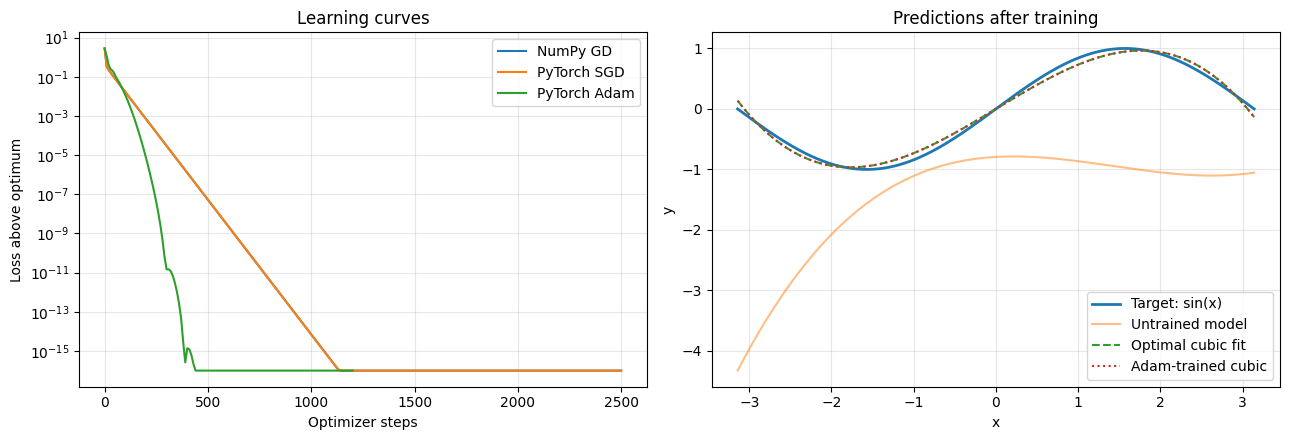

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, history in [('NumPy GD', history_numpy),
                      ('PyTorch SGD', history_sgd),
                      ('PyTorch Adam', history_adam)]:
    excess = np.maximum(history[:, 1] - optimal_loss, 1e-16)
    axes[0].semilogy(history[:, 0], excess, label=name)
axes[0].set(xlabel='Optimizer steps', ylabel='Loss above optimum',
            title='Learning curves')
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(x, y, linewidth=2, label='Target: sin(x)')
axes[1].plot(x, X @ initial_theta, alpha=0.5, label='Untrained model')
axes[1].plot(x, X @ theta_optimal, '--', label='Optimal cubic fit')
axes[1].plot(x, X @ theta_adam, ':', label='Adam-trained cubic')
axes[1].set(xlabel='x', ylabel='y', title='Predictions after training')
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Compare accuracy and execution time

The final loss and distance to the reference coefficients measure convergence. The times shown below describe **one run** on the current hardware; they should not be presented as statistically reliable speed benchmarks. For small problems, framework overhead can dominate execution time.

In [ ]:
print(f'{"Method":<21} {"Time (s)":>11} {"Final loss":>15} {"Parameter error":>18}')
for name, elapsed, theta in [
    ('Direct solve', time_direct, theta_optimal),
    ('NumPy GD', time_numpy, theta_numpy),
    ('PyTorch SGD', time_sgd, theta_sgd),
    ('PyTorch Adam', time_adam, theta_adam),
]:
    difference = np.linalg.norm(theta - theta_optimal)
    print(f'{name:<21} {elapsed:11.5f} {numpy_loss(theta):15.9f} {difference:18.3e}')

# Confirm that each iterative method has reached a comparably good objective.
for candidate in (theta_numpy, theta_sgd, theta_adam):
    assert numpy_loss(candidate) >= optimal_loss - 1e-10
    assert numpy_loss(candidate) - optimal_loss < 1e-5

Method                   Time (s)      Final loss    Parameter error
Direct solve              0.00039     0.019169628          0.000e+00
NumPy GD                  0.10380     0.019169628          2.279e-14
PyTorch SGD               0.97570     0.019169628          2.232e-14
PyTorch Adam              0.60371     0.019169628          3.385e-15


## 9. Interpret the fitted polynomial in the original variable

We trained on $z=x/\pi$. Thus the coefficients are expressed in powers of $z$, **not** directly in powers of $x$. The conversion is

$$\sum_{j=0}^{3}\theta_j (x/\pi)^j=\sum_{j=0}^{3}c_jx^j,\qquad c_j=\theta_j/\pi^j.$$

This also illustrates the difference between **feature scaling**, which changes how parameters are represented, and the underlying function being fitted.

In [ ]:
coefficients_in_x = theta_optimal / np.pi ** np.arange(DEGREE + 1)
for power, coefficient in enumerate(coefficients_in_x):
    print(f'Coefficient of x^{power}: {coefficient:+.8f}')

# Both representations must make identical predictions.
np.testing.assert_allclose(
    X @ theta_optimal,
    np.polynomial.polynomial.polyval(x, coefficients_in_x),
    atol=1e-12
)

Coefficient of x^0: -0.00000000
Coefficient of x^1: +0.81881887
Coefficient of x^2: -0.00000000
Coefficient of x^3: -0.08734695


## 10. A compact PyTorch model using `torch.nn.Linear`

So far, we explicitly stored four coefficients. PyTorch offers standard neural-network building blocks in `torch.nn`. Despite its name, `nn.Linear` computes an **affine** transformation $u\mapsto uW^\mathsf T+b$.

We can supply the features $[z,z^2,z^3]$ and let its `bias` represent the constant coefficient. This produces the **same cubic model**, not a deep neural network. Notice the input now has shape `(N, 3)` and the output has shape `(N, 1)`; we squeeze the final dimension to compare with `y`.

For an exact comparison, the ridge penalty must include **both** `weight` and `bias`.

### Optional extension: a ready-made PyTorch layer

`nn.Linear` sounds like a straight-line model, but it combines however many **supplied input columns** we provide. Giving it $z,z^2,z^3$ and a separate bias produces the same cubic prediction. We exclude the constant column because the layer's `bias` already represents the intercept; using both would duplicate that role.

In [ ]:
features = torch.as_tensor(X[:, 1:], dtype=DTYPE)  # Exclude constant column.
model = torch.nn.Linear(in_features=DEGREE, out_features=1, bias=True, dtype=DTYPE)

# Initialize weight and bias to match the earlier theta exactly.
with torch.no_grad():
    model.weight.copy_(torch.tensor(initial_theta[1:][None, :], dtype=DTYPE))
    model.bias.copy_(torch.tensor([initial_theta[0]], dtype=DTYPE))

def model_loss():
    predicted = model(features).squeeze(-1)
    mse = torch.mean((predicted - y_torch) ** 2)
    ridge = REGULARIZATION * (model.weight.square().sum() + model.bias.square().sum())
    return mse + ridge

print('Feature shape:', tuple(features.shape))
print('Model output shape:', tuple(model(features).shape))
print('Number of trainable parameters:', sum(p.numel() for p in model.parameters()))
print('Initial nn.Linear loss:', model_loss().item())
np.testing.assert_allclose(model_loss().item(), numpy_loss(initial_theta))

optimizer = torch.optim.Adam(model.parameters(), lr=0.05)
for _ in range(1200):
    optimizer.zero_grad(set_to_none=True)
    loss = model_loss()
    loss.backward()
    optimizer.step()

with torch.no_grad():
    learned_theta = np.r_[model.bias.item(), model.weight.detach().numpy().ravel()]
print('Final nn.Linear loss:', numpy_loss(learned_theta))
print('Distance to reference parameters:', np.linalg.norm(learned_theta-theta_optimal))
assert numpy_loss(learned_theta) - optimal_loss < 1e-5

Feature shape: (2000, 3)
Model output shape: (2000, 1)
Number of trainable parameters: 4
Initial nn.Linear loss: 2.7911098261027645
Final nn.Linear loss: 0.019169628199232177
Distance to reference parameters: 2.811465822948227e-15


## 11. Graded homework: explore the model (100 points)

**Submission:** Upload **one executed `.ipynb` file** with all required plots visible and written answers entered in the designated Markdown answer cells. You may also export a PDF for convenient reading, but the notebook is the graded artifact. Keep the guided-example cells intact and working. **Do not submit only screenshots.**

**Rule:** For each experiment, state what you changed, show numerical evidence or a plot, and explain what it means in your own words. Run **Kernel → Restart & Run All** (or Colab **Runtime → Run all**) before submitting.

### Assignment 1 — Understand features and the intercept (20 points)

**A1 (8 pts).** By hand, write the four-element feature row for $z=-0.5$ and compute the prediction for $\boldsymbol\theta=(1,2,0,-1)$. Explain each number in the row.

**A2 (6 pts).** Explain why the first feature column consists of ones. What restriction would the model have if both this column and a separate bias were absent?

**A3 (6 pts).** Run the starter code below for both $z=-0.5$ and $z=0$. Check your A1 calculation and explain the role of $\theta_0$.


In [ ]:
# A3: starter code. Replace the TODOs and run.
theta_homework = np.array([1.0, 2.0, 0.0, -1.0])
for z_value in [-0.5, 0.0]:
    row = np.array([1.0, z_value, z_value**2, z_value**3])
    print(f'z={z_value:+.1f}  row={row}  prediction={row @ theta_homework:.6f}')

z=-0.5  row=[ 1.    -0.5    0.25  -0.125]  prediction=0.125000
z=+0.0  row=[1. 0. 0. 0.]  prediction=1.000000


**A1–A3 written response (replace this prompt with your answer):**

> Your calculation and explanation here.

### Assignment 2 — Derivatives and one optimization step (20 points)

**B1 (8 pts).** For the toy loss $L(w)=(w-2)^2$, calculate $L(0)$, $dL/dw$ at $w=0$, and the updated weight after one step with learning rate $\eta=0.1$.

**B2 (6 pts).** Explain in words why the update subtracts the gradient rather than adding it.

**B3 (6 pts).** Use the code below to run 12 steps starting from $w=0$. Plot the loss and describe its trend. State whether the weight is moving toward 2.


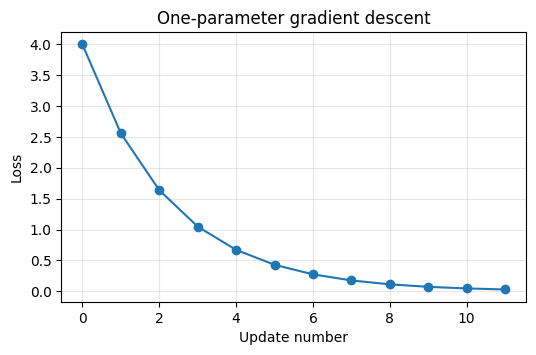

Weight after 12 steps: 1.862561046528


In [ ]:
# B3: complete training example for one adjustable number
w = 0.0
step_size = 0.1
loss_history_toy = []
for step in range(12):
    loss_history_toy.append((w - 2)**2)
    gradient = 2 * (w - 2)
    w = w - step_size * gradient
plt.figure(figsize=(6, 3.5))
plt.plot(range(len(loss_history_toy)), loss_history_toy, 'o-')
plt.xlabel('Update number'); plt.ylabel('Loss'); plt.title('One-parameter gradient descent')
plt.grid(alpha=0.3); plt.show()
print('Weight after 12 steps:', w)

**B1–B3 written response:**

> Your calculation, plot interpretation, and explanation here.

### Assignment 3 — Learning-rate experiment (20 points)

**C1 (12 pts).** Run the full NumPy optimizer with three learning rates: $0.1\eta_0$, $\eta_0$, and $2.2\eta_0$, where $\eta_0$ is the automatically selected baseline. Plot **loss versus step** on the same figure, using at most 150 iterations. The large rate may diverge; extremely large losses are expected.

**C2 (8 pts).** Report the final finite loss or divergence for each rate; explain which is slow and which is unstable. The same starting parameters must be used for every run.


0.1 × baseline: final recorded loss = 0.284853
1.0 × baseline: final recorded loss = 0.0225645
2.2 × baseline: final recorded loss = 1.23464e+24


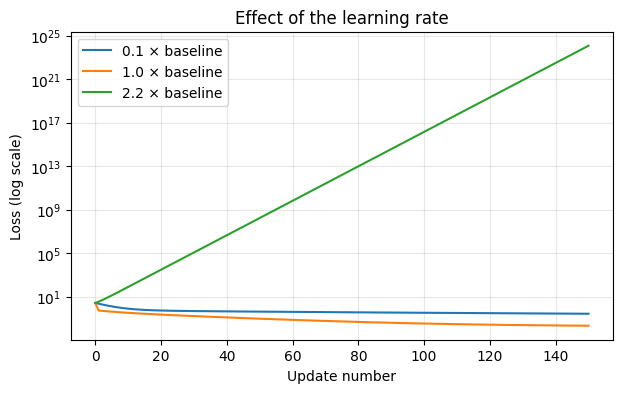

In [ ]:
# C1: reusable gradient descent code with a freely chosen learning rate
def gd_for_homework(start_theta, rate, steps=150):
    current = start_theta.copy()
    losses = [numpy_loss(current)]
    for _ in range(steps):
        current = current - rate * numpy_gradient(current)
        losses.append(numpy_loss(current))
        if not np.isfinite(losses[-1]):
            break
    return np.asarray(losses)

plt.figure(figsize=(7, 4))
for multiplier in [0.1, 1.0, 2.2]:
    values = gd_for_homework(initial_theta, multiplier * learning_rate)
    plt.semilogy(range(len(values)), values, label=f'{multiplier} × baseline')
    print(f'{multiplier} × baseline: final recorded loss = {values[-1]:.6g}')
plt.xlabel('Update number'); plt.ylabel('Loss (log scale)')
plt.title('Effect of the learning rate'); plt.legend(); plt.grid(alpha=0.3); plt.show()

**C1–C2 written response:**

> Your observations and explanation here.

### Assignment 4 — Polynomial degree and generalization (25 points)

**D1 (10 pts).** Fit degrees 1, 3, 5, and 9 using a **training set** and evaluate predictions on separate **test points**. Use the starter cell; it uses an ordinary least-squares solver to isolate the effect of polynomial degree from the optimizer.

**D2 (8 pts).** Record the test MSE for each degree in a table and plot the fitted curves. Which degree works best *on these test points*? Explain why a more flexible polynomial can follow sine more closely.

**D3 (7 pts).** In your own words, explain the difference between a *training* error and a *test* error. Why should the test data not be used to choose coefficients? (This exercise illustrates the idea; for robust comparisons, use genuinely independent, representative datasets.)


Degree | Train MSE | Test MSE
     1 | 0.2243646 | 0.1965569
     3 | 0.0057537 | 0.0048310
     5 | 0.0000253 | 0.0000231
     9 | 0.0000000 | 0.0000000


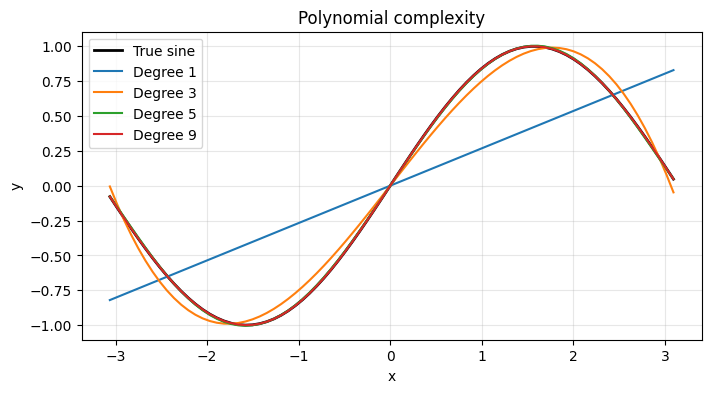

In [ ]:
# D1: train/test split; use fixed, reproducible samples
z_train = np.linspace(-1, 1, 25)
y_train = np.sin(np.pi * z_train)
z_test = np.linspace(-0.98, 0.98, 80) + 0.005  # Different inputs from training grid
y_test = np.sin(np.pi * z_test)
plt.figure(figsize=(8, 4))
plt.plot(np.pi * z_test, y_test, 'k-', linewidth=2, label='True sine')
print('Degree | Train MSE | Test MSE')
for degree in [1, 3, 5, 9]:
    A_train = np.polynomial.polynomial.polyvander(z_train, degree)
    A_test = np.polynomial.polynomial.polyvander(z_test, degree)
    weights, *_ = np.linalg.lstsq(A_train, y_train, rcond=None)
    train_mse = np.mean((A_train @ weights - y_train)**2)
    test_mse = np.mean((A_test @ weights - y_test)**2)
    print(f'{degree:>6} | {train_mse:.7f} | {test_mse:.7f}')
    plt.plot(np.pi*z_test, A_test @ weights, label=f'Degree {degree}')
plt.xlabel('x'); plt.ylabel('y'); plt.title('Polynomial complexity')
plt.legend(); plt.grid(alpha=0.3); plt.show()

**D1–D3 written response (include your MSE table):**

> Your table and interpretation here.

### Assignment 5 — Explain automatic differentiation (15 points)

**E1 (6 pts).** For $f(a)=a^3-4a$, calculate $df/da$ by hand and evaluate it at $a=3$.

**E2 (5 pts).** Modify the example below and confirm PyTorch's `.backward()` gives the same answer.

**E3 (4 pts).** In two or three sentences, explain what `.grad`, `zero_grad()`, and `optimizer.step()` do.


In [ ]:
# E2: demonstrate differentiation with PyTorch
a_hw = torch.tensor(3.0, dtype=DTYPE, requires_grad=True)
f_hw = a_hw**3 - 4*a_hw
f_hw.backward()
print('Autograd derivative:', a_hw.grad.item())
print('Derivative calculated from 3*a**2 - 4:', (3*a_hw.item()**2 - 4))

Autograd derivative: 23.0
Derivative calculated from 3*a**2 - 4: 23.0


**E1–E3 written response:**

> Your derivation and explanation here.

## 12. Rubric and submission checklist

| Item | Points | What earns full credit |
|---|---:|---|
| A. Features and intercept | 20 | Correct expansion, arithmetic, and intercept reasoning |
| B. Gradient descent basics | 20 | Correct derivative/update, working plot, clear explanation |
| C. Learning rate | 20 | Fair comparison, labeled plot, accurate stability interpretation |
| D. Degree and test error | 25 | All four degrees, MSE table, curves, correct generalization discussion |
| E. PyTorch autograd | 15 | Correct derivative, verified code, accurate API explanation |
| **Total** | **100** | |

**Before submitting:**

- [ ] Notebook runs top to bottom without errors.
- [ ] All five written-answer placeholders have been replaced with substantive answers.
- [ ] Required figures have visible labels and legends where applicable.
- [ ] Degree experiment includes a numeric table of test errors.
- [ ] Changes are explained in words, not only shown as code.
- [ ] Submit the executed `.ipynb` file.


## 13. Key takeaways

A model turns inputs into predictions. Polynomial expansion creates powers of the same input as separate features; a leading column of ones enables a trainable intercept. A loss measures error, and a gradient tells us how to change coefficients to reduce it. NumPy lets us program the gradient explicitly; PyTorch can calculate it automatically. Training error measures fit to the data used to learn, while test error estimates performance on points not used to fit the coefficients.
